# New Dataset – Step 5: Advanced Metrics

Notebooks 1–4 used the 10 metrics from the paper (TTR, LD, WR, MDD, SI, Cross, WSF, LIX, FRE, Fog).
These metrics only measure **how complex** a text is. A text can be very "easy" because important content was deleted.
So this notebook adds measures for **lexical diversity, predictability, Easy Language rules, meaning preservation and an LLM judge**.
Then it runs the **same three experiments** with them:

1. **Legal vs. Medical** – Welch t-test, Cohen's d, Holm correction (as in notebook 2)
2. **Which model is best?** – Friedman, Kendall's W, Wilcoxon + Bonferroni (as in notebook 3)
3. **Which approach is best?** – Friedman + pairwise paired tests with Bonferroni (as in notebook 4)

| Group | Metric | Meaning | Better |
|---|---|---|---|
| **Lexical** | `MATTR` | Moving-Average Type-Token Ratio (window = 50 words). Unlike TTR, it does not depend on text length | ↓ |
| | `MTLD` | Measure of Textual Lexical Diversity (McCarthy & Jarvis 2010). Also independent of length | ↓ |
| | `Zipf` | mean word frequency on the Zipf scale (`wordfreq`, 1 = very rare … 7 = very common) | ↑ |
| | `RareWords` | % of words with Zipf < 3 (rarer than about 1 per million words) | ↓ |
| **Surprisal** | `Surprisal` | mean surprisal per word in bits, from the German language model `dbmdz/german-gpt2`. Lower = more predictable = easier to process | ↓ |
| | `Surprisal_SD` | standard deviation of word surprisal. Lower = information is spread more evenly (Uniform Information Density) | ↓ |
| **Easy Language rules** | `ASL` | average sentence length (words) | ↓ |
| | `LongSent` | % of sentences with more than 15 words | ↓ |
| | `Passive` | % of sentences with a *werden*-passive | ↓ |
| | `Genitive` | genitive nouns per 100 words | ↓ |
| | `Subjunctive` | Konjunktiv verb forms per 100 words | ↓ |
| | `LongWords` | % of words with more than 13 letters that are not hyphenated (Easy Language splits compounds: *Spiel-Geld*) | ↓ |
| | `EL_Compliance` | % of sentences that follow **all** 6 sentence rules (≤ 15 words, no subordinate clause, no passive, no Konjunktiv, no genitive, no long unhyphenated word) | ↑ |
| **Meaning preservation** (compared with the German source) | `Coverage` | how much of the source content is still in the output: for every source sentence, the highest cosine similarity to any output sentence (multilingual sentence embeddings), averaged | ↑ |
| | `Precision` | the other direction: for every output sentence, the highest similarity to any source sentence. Low = new content (explanations or hallucinations) | ↑ |
| | `NumberRecall` | % of the numbers in the source (amounts, dates, ages …) that also appear in the output | ↑ |
| **LLM judge** (GWDG API) | `Judge_EasyLanguage`, `Judge_Completeness`, `Judge_Accuracy`, `Judge_Grammar`, `Judge_Audience`, `Judge_Overall` | 1–5 ratings by an independent LLM | ↑ |

`LengthRatio` (output words / source words) is reported descriptively only, because it has no "better" direction.

**Original** = official German source text (`Source_Texts_German`). Meaning-preservation and judge scores are only computed for the 3 approaches.


In [1]:
# !pip install wordfreq openai pyphen
# !python -m spacy download de_core_news_lg

In [2]:
import os
import re
import json
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
import torch
from wordfreq import zipf_frequency
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon, spearmanr
from itertools import combinations
from statsmodels.stats.multitest import multipletests

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = "New dataset"
RESULTS_DIR = os.path.join(DATA_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

MODELS = {
    "DeepSeek-V4-Flash": "deepseek-v4-flash-0731",
    "Gemma-4-31B":       "gemma-4-31b-it",
    "Llama-3.1-8B":      "meta-llama-3.1-8b-instruct",
    "Qwen3.5-397B":      "qwen3.5-397b-a17b",
}
APPROACHES = ["Approach_1", "Approach_2", "Approach_3"]
VERSIONS = {
    "Original":   "Source_Texts_German",
    "Approach_1": "{model}/Approach_1/DE_translated_easy_from_easy",
    "Approach_2": "{model}/Approach_2/DE_translated_easy",
    "Approach_3": "{model}/Approach_3/DE_easy_direct",
}
TEXT_IDS = [f"{domain}_{i}" for domain in ["legal", "medical"] for i in range(1, 6)]

MODEL_COLORS = {"DeepSeek-V4-Flash": "#1f77b4", "Gemma-4-31B": "#ff7f0e", "Llama-3.1-8B": "#2ca02c", "Qwen3.5-397B": "#d62728"}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## Loading the texts
Same cleaning as in notebook 1. The raw text is kept as well, because the LLM judge sees the original formatting.

In [3]:
def clean_text(text):
    lines = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("Hier ist"):
            continue
        if set(line) <= set("-*_=# "):
            continue
        line = re.sub(r"^[#>*•\-–\s]+", "", line)
        line = re.sub(r"^\d+[.)]\s+", "", line)
        line = line.replace("**", "").replace("__", "").replace("*", "")
        line = line.strip()
        if not line:
            continue
        if line[-1] not in ".!?":
            line += "."
        lines.append(line)
    return " ".join(lines)


def read(path):
    with open(path, encoding="utf-8") as f:
        return f.read()


def load_model_texts(folder_name):
    rows = []
    for text_id in TEXT_IDS:
        row = {"ID": text_id, "Domain": text_id.split("_")[0].capitalize()}
        for version, folder in VERSIONS.items():
            raw = read(os.path.join(DATA_DIR, folder.format(model=folder_name), f"DE_{text_id}.txt"))
            row[f"{version}_raw"] = raw.strip()
            row[version] = clean_text(raw)
        rows.append(row)
    return pd.DataFrame(rows)


texts = {name: load_model_texts(folder) for name, folder in MODELS.items()}
texts["Qwen3.5-397B"][["ID", "Domain", "Original", "Approach_1"]].head(3)

,ID,Domain,Original,Approach_1
0,legal_1,Legal,Verbraucherschutzbehörden verstärken Maßnahmen zum Schutz der Rechte von Spi...,Verbraucher-Gruppen schützen Rechte von Spielenden. Heute arbeiten Behörden ...
1,legal_2,Legal,"Kommission verhängt Geldbuße in Höhe von 40 Mio. EUR gegen Kingspan, weil da...",Europäische Kommission bestraft Firma Kingspan mit 40 Millionen Euro. Die Eu...
2,legal_3,Legal,Kommission registriert Europäische Bürgerinitiative für souveräne europäisch...,Europäische Kommission nimmt Vorschlag von Bürgern an. Es geht um eine Inter...


In [4]:
nlp = spacy.load("de_core_news_lg")

_doc_cache = {}
def get_doc(text):
    if text not in _doc_cache:
        _doc_cache[text] = nlp(text)
    return _doc_cache[text]


def words_of(text):
    return [t.text for t in get_doc(text) if t.is_alpha]

# 1. Lexical diversity and word frequency

### MATTR (Moving-Average Type-Token Ratio)
TTR depends on text length: longer texts automatically get a lower TTR. MATTR slides a window of 50 words over the text,
computes the TTR in every window and takes the average, so texts of different lengths can be compared.

### MTLD (Measure of Textual Lexical Diversity)
MTLD counts how many words in a row are needed before the TTR drops below 0.72 (one "factor").
MTLD = number of words / number of factors, averaged over a forward and a backward pass. Higher = more diverse vocabulary.

### Zipf frequency and rare words
`wordfreq` gives each German word a frequency on the Zipf scale (log10 of frequency per billion words).
Easy Language should use **frequent** words, so a higher mean Zipf value and fewer rare words (Zipf < 3) are better.
This is a more direct measure than Word Rarity (WR) from the paper, which only checked whether spaCy has a vector for the word.

In [5]:
def compute_mattr(text, window=50):
    words = [w.lower() for w in words_of(text)]
    if len(words) <= window:
        return len(set(words)) / len(words) if words else 0.0
    ttrs = [len(set(words[i:i + window])) / window for i in range(len(words) - window + 1)]
    return round(float(np.mean(ttrs)), 4)


def _mtld_pass(words, threshold=0.72):
    factors, types, count = 0.0, set(), 0
    for w in words:
        types.add(w)
        count += 1
        if len(types) / count <= threshold:
            factors += 1
            types, count = set(), 0
    if count > 0:                                   # partial factor for the rest
        ttr = len(types) / count
        factors += (1 - ttr) / (1 - threshold)
    return len(words) / factors if factors > 0 else len(words)


def compute_mtld(text):
    words = [w.lower() for w in words_of(text)]
    if not words:
        return 0.0
    return round((_mtld_pass(words) + _mtld_pass(words[::-1])) / 2, 2)


def compute_zipf(text):
    zipfs = [zipf_frequency(w, "de") for w in words_of(text)]
    return round(float(np.mean(zipfs)), 3) if zipfs else 0.0


def compute_rare_words(text):
    zipfs = [zipf_frequency(w, "de") for w in words_of(text)]
    return round(100 * np.mean([z < 3 for z in zipfs]), 2) if zipfs else 0.0

# 2. Surprisal

Surprisal is how unexpected a word is in its context: $s(w_i) = -\log_2 P(w_i \mid w_1 \dots w_{i-1})$ (in bits).
It is a well-known predictor of reading time and processing effort (Hale 2001; Levy 2008).

* Probabilities come from the German GPT-2 model `dbmdz/german-gpt2`. This model is **not related** to any of the 4 tested LLMs.
* A word's surprisal is the sum of the surprisals of its sub-word tokens.
* Long texts are processed with a sliding window (1024 tokens, stride 512), so every token has at least 512 tokens of context.
* `Surprisal` = mean surprisal per word, and `Surprisal_SD` = its standard deviation. A low SD means the information is spread evenly (Uniform Information Density).

Note: hyphenated Easy Language compounds (*Spiel-Geld*) are unusual in normal German, so the language model may find them surprising.

In [6]:
LM_NAME = "dbmdz/german-gpt2"
lm_tokenizer = AutoTokenizer.from_pretrained(LM_NAME)
lm_model = AutoModelForCausalLM.from_pretrained(LM_NAME).to(device).eval()


# The tokenizer's BOS id (50265) is outside the model vocabulary (50265 entries),
# so a "." token is used as neutral start context for the first word.
START_ID = lm_tokenizer(".").input_ids[0]

def token_surprisals(text, window=1024, stride=512):
    ids = lm_tokenizer(text).input_ids
    ids = torch.tensor([START_ID] + ids)
    surprisal = np.full(len(ids), np.nan)
    done_until = 1                                   # position 0 is the start token
    for start in range(0, len(ids), stride):
        end = min(start + window, len(ids))
        chunk = ids[start:end].unsqueeze(0).to(device)
        with torch.no_grad():
            logits = lm_model(chunk).logits[0].float()
        log_probs = torch.log_softmax(logits[:-1], dim=-1)
        s = -log_probs.gather(1, chunk[0, 1:, None])[:, 0] / math.log(2)
        s = s.cpu().numpy()
        for pos in range(max(done_until, start + 1), end):
            surprisal[pos] = s[pos - start - 1]
        done_until = end
        if end == len(ids):
            break
    tokens = lm_tokenizer.convert_ids_to_tokens(ids.tolist())
    return tokens[1:], surprisal[1:]


_surprisal_cache = {}
def word_surprisals(text):
    if text in _surprisal_cache:
        return _surprisal_cache[text]
    tokens, surprisal = token_surprisals(text)
    words, current, current_s = [], "", 0.0
    for tok, s in zip(tokens, surprisal):
        piece = tok.replace("Ġ", " ")
        if piece.startswith(" ") or not re.search(r"\w", piece) or not current:
            if current:
                words.append((current, current_s))
            current, current_s = piece.strip(), s
        else:
            current += piece
            current_s += s
    if current:
        words.append((current, current_s))
    values = [s for w, s in words if re.search(r"[A-Za-zÄÖÜäöüß]", w)]
    _surprisal_cache[text] = values
    return values


def compute_surprisal(text):
    return round(float(np.mean(word_surprisals(text))), 3)


def compute_surprisal_sd(text):
    return round(float(np.std(word_surprisals(text), ddof=1)), 3)


print(compute_surprisal("Das Medikament darf nicht mehr verkauft werden."),
      compute_surprisal("Die Genehmigung für das Inverkehrbringen wird widerrufen."))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:  26%|██▋       | 39/148 [00:00<00:00, 367.96it/s]

Loading weights:  51%|█████▏    | 76/148 [00:00<00:00, 147.02it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 312.72it/s]


[transformers] GPT2LMHeadModel LOAD REPORT from: dbmdz/german-gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


6.706 7.226


# 3. Easy Language rule checks

Rule-based checks of central sentence- and word-level rules of German Easy Language (Maaß 2015; Bredel & Maaß 2016; DIN SPEC 33429):

| Rule | Check (spaCy `de_core_news_lg`) |
|---|---|
| short sentences | sentence has at most 15 words |
| no subordinate clauses | no subordinating conjunction (`KOUS`) and no relative pronoun (`PRELS`, `PRELAT`) |
| active voice | no past participle (`VVPP`) that depends on *werden* |
| no Konjunktiv | no verb with `Mood=Sub` |
| no genitive | no noun with `Case=Gen` |
| split long compounds | no word with more than 13 letters without a hyphen |

`EL_Compliance` = % of sentences that follow **all six** rules. The single rules are also reported as separate metrics.

In [7]:
def sentence_checks(sent):
    words = [t for t in sent if t.is_alpha or "-" in t.text and any(c.isalpha() for c in t.text)]
    return {
        "short": len(words) <= 15,
        "no_subordinate": not any(t.tag_ in {"KOUS", "PRELS", "PRELAT"} for t in sent),
        "no_passive": not any(t.tag_ == "VVPP" and t.head.lemma_ == "werden" for t in sent),
        "no_subjunctive": not any("Sub" in t.morph.get("Mood") for t in sent),
        "no_genitive": not any(t.pos_ in {"NOUN", "PROPN"} and "Gen" in t.morph.get("Case") for t in sent),
        "no_long_word": not any(t.is_alpha and len(t.text) > 13 for t in sent),
        "n_words": len(words),
    }


_rule_cache = {}
def rule_stats(text):
    if text not in _rule_cache:
        doc = get_doc(text)
        checks = pd.DataFrame([sentence_checks(s) for s in doc.sents])
        n_words = len(words_of(text))
        rule_cols = ["short", "no_subordinate", "no_passive", "no_subjunctive", "no_genitive", "no_long_word"]
        _rule_cache[text] = {
            "ASL": round(checks["n_words"].mean(), 2),
            "LongSent": round(100 * (~checks["short"]).mean(), 2),
            "Passive": round(100 * (~checks["no_passive"]).mean(), 2),
            "Genitive": round(100 * sum(1 for t in doc if t.pos_ in {"NOUN", "PROPN"} and "Gen" in t.morph.get("Case")) / n_words, 2),
            "Subjunctive": round(100 * sum(1 for t in doc if "Sub" in t.morph.get("Mood")) / n_words, 2),
            "LongWords": round(100 * sum(1 for t in doc if t.is_alpha and len(t.text) > 13) / n_words, 2),
            "EL_Compliance": round(100 * checks[rule_cols].all(axis=1).mean(), 2),
        }
    return _rule_cache[text]


rule_stats("Die Kommission hat beschlossen, Bulgarien zu verklagen, weil die Vorschriften nicht umgesetzt wurden. Das ist gut.")

{'ASL': np.float64(8.0),
 'LongSent': np.float64(0.0),
 'Passive': np.float64(50.0),
 'Genitive': 0.0,
 'Subjunctive': 0.0,
 'LongWords': 0.0,
 'EL_Compliance': np.float64(50.0)}

# 4. Meaning preservation

Simplification metrics reward deleting content. These metrics check how much of the **German source text** is still in the output.

* Each sentence is embedded with the multilingual sentence encoder `paraphrase-multilingual-mpnet-base-v2` (mean pooling).
* **Coverage** (recall): for every **source** sentence, take the most similar output sentence; Coverage is the average of these best similarities. Low = content was lost.
* **Precision**: for every **output** sentence, take the most similar source sentence and average. Low = the output contains content that is not in the source. This can be helpful explanations, which Easy Language allows, or hallucinations.
* **NumberRecall**: % of the numbers in the source (e.g. *40*, *65*, *2025*, *14*) that also appear in the output. Numbers are critical facts in legal and medical texts. Texts without numbers get 100.
* **LengthRatio**: words in the output / words in the source (descriptive only).

In [8]:
EMB_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
emb_tokenizer = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).to(device).eval()


def embed(sentences, batch_size=32):
    vectors = []
    for i in range(0, len(sentences), batch_size):
        batch = emb_tokenizer(sentences[i:i + batch_size], padding=True, truncation=True,
                              max_length=256, return_tensors="pt").to(device)
        with torch.no_grad():
            out = emb_model(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        v = (out * mask).sum(1) / mask.sum(1)                  # mean pooling
        vectors.append(torch.nn.functional.normalize(v, dim=-1).cpu())
    return torch.cat(vectors).numpy()


_emb_cache = {}
def sentence_embeddings(text):
    if text not in _emb_cache:
        sents = [s.text for s in get_doc(text).sents if any(c.isalpha() for c in s.text)]
        _emb_cache[text] = embed(sents)
    return _emb_cache[text]


NUMBER_RE = re.compile(r"\d+(?:[.,]\d+)?")

def meaning_stats(source, output):
    sim = sentence_embeddings(source) @ sentence_embeddings(output).T
    src_numbers = set(NUMBER_RE.findall(source))
    out_numbers = set(NUMBER_RE.findall(output))
    return {
        "Coverage": round(float(sim.max(axis=1).mean()), 4),
        "Precision": round(float(sim.max(axis=0).mean()), 4),
        "NumberRecall": round(100 * len(src_numbers & out_numbers) / len(src_numbers), 2) if src_numbers else 100.0,
        "LengthRatio": round(len(words_of(output)) / len(words_of(source)), 3),
    }

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  24%|██▎       | 47/199 [00:00<00:00, 469.12it/s]

Loading weights:  47%|████▋     | 94/199 [00:00<00:00, 445.98it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 670.05it/s]

# 5. Computing all automatic metrics

In [9]:
LEXICAL = ["MATTR", "MTLD", "Zipf", "RareWords"]
SURPRISAL = ["Surprisal", "Surprisal_SD"]
EL_RULES = ["ASL", "LongSent", "Passive", "Genitive", "Subjunctive", "LongWords", "EL_Compliance"]
MEANING = ["Coverage", "Precision", "NumberRecall"]
JUDGE = ["Judge_EasyLanguage", "Judge_Completeness", "Judge_Accuracy", "Judge_Grammar", "Judge_Audience", "Judge_Overall"]

HIGHER_BETTER = ["Zipf", "EL_Compliance", "Coverage", "Precision", "NumberRecall"] + JUDGE

TEXT_FUNCTIONS = {
    "MATTR": compute_mattr, "MTLD": compute_mtld, "Zipf": compute_zipf, "RareWords": compute_rare_words,
    "Surprisal": compute_surprisal, "Surprisal_SD": compute_surprisal_sd,
}


def compute_advanced(df):
    df = df.copy()
    for version in VERSIONS:
        for metric, func in TEXT_FUNCTIONS.items():
            df[f"{metric}_{version}"] = df[version].apply(func)
        rules = df[version].apply(rule_stats).apply(pd.Series)
        for metric in EL_RULES:
            df[f"{metric}_{version}"] = rules[metric]
        if version == "Original":
            for metric in MEANING + ["LengthRatio"]:
                df[f"{metric}_{version}"] = np.nan
        else:
            meaning = df.apply(lambda r: meaning_stats(r["Original"], r[version]), axis=1).apply(pd.Series)
            for metric in MEANING + ["LengthRatio"]:
                df[f"{metric}_{version}"] = meaning[metric]
    return df


adv = {}
for name, folder in MODELS.items():
    adv[name] = compute_advanced(texts[name])
    print("done:", name)

done: DeepSeek-V4-Flash


done: Gemma-4-31B


done: Llama-3.1-8B


done: Qwen3.5-397B


# 6. LLM as a judge (GWDG API)

Each of the 120 Easy Language outputs (4 models × 3 approaches × 10 texts) is rated by an **independent LLM**
through the OpenAI-compatible GWDG API (`https://chat-ai.academiccloud.de/v1`), the same platform that was used to generate the data.

* The judge is **not** one of the tested models: it prefers *Mistral Large*, then *gpt-oss-120b*, then *Llama-3.3-70B*. You can override this with the env variable `GWDG_JUDGE_MODEL`.
* **Blind:** the judge does not see which model or approach produced the text.
* It sees the official German source text and the Easy Language output, and rates both from 1 to 5. The rubric follows Easy Language rules and the error categories in the paper (Section 4.3):

| Criterion | 5 = |
|---|---|
| `EasyLanguage` | follows the Easy Language rules (short main clauses, frequent words, difficult words explained, compounds split, active voice, no genitive/Konjunktiv, clear structure) |
| `Completeness` | all information important for the reader is kept |
| `Accuracy` | no wrong statements, distortions or hallucinations |
| `Grammar` | correct German (no missing articles or verbs, etc.) |
| `Audience` | respectful and appropriate for adults (formal *Sie*, not childish, not stigmatising) |
| `Overall` | overall quality as an Easy Language translation |

* `temperature = 0`. Results are cached in `New dataset/results/LLM_Judge_Scores.csv`; only missing ratings are requested.
* **To run:** set the environment variable `GWDG_API_KEY` before starting Jupyter. Without a key, the notebook uses the cached ratings, or skips the judge metrics if there are none.

In [10]:
from openai import OpenAI

GWDG_BASE_URL = "https://chat-ai.academiccloud.de/v1"
JUDGE_PREFERENCES = ["mistral-large", "gpt-oss-120b", "llama-3.3-70b"]
JUDGE_FILE = os.path.join(RESULTS_DIR, "LLM_Judge_Scores.csv")
JUDGE_CRITERIA = ["EasyLanguage", "Completeness", "Accuracy", "Grammar", "Audience", "Overall"]

JUDGE_SYSTEM = """You are an expert evaluator of German Easy Language (Leichte Sprache) translations, following the rules of
Maaß (2015, Leichte Sprache. Das Regelbuch), Bredel & Maaß (2016) and DIN SPEC 33429. You are strict, consistent and objective."""

JUDGE_PROMPT = """Rate the following translation of a German source text into German Easy Language (Leichte Sprache).

Rate each criterion on a scale from 1 (very poor) to 5 (excellent):
- EasyLanguage: Does the text follow Easy Language rules? (short main clauses, one statement per sentence, no subordinate clauses,
  frequent everyday words, difficult words explained, long compounds split with hyphen or mediopoint, active voice,
  no genitive, no Konjunktiv, numbers as digits, clear structure)
- Completeness: Is all information that is important for the reader kept? (Omitting less important details is allowed in Easy Language.)
- Accuracy: Is all information correct? (no wrong statements, distortions or hallucinated facts)
- Grammar: Is the German grammatically correct? (e.g. no missing articles or verbs, correct inflection)
- Audience: Is the text respectful and appropriate for adult readers? (formal "Sie" in official texts, not childish, not stigmatising)
- Overall: Overall quality as an Easy Language translation of the source.

Answer ONLY with a JSON object of this form:
{{"EasyLanguage": <1-5>, "Completeness": <1-5>, "Accuracy": <1-5>, "Grammar": <1-5>, "Audience": <1-5>, "Overall": <1-5>, "Main_problem": "<one short sentence>"}}

### SOURCE TEXT (standard German)
{source}

### EASY LANGUAGE TRANSLATION
{output}"""


def parse_judge_answer(answer):
    match = re.search(r"\{.*\}", answer, re.DOTALL)
    data = json.loads(match.group(0))
    result = {c: int(data[c]) for c in JUDGE_CRITERIA}
    result["Main_problem"] = str(data.get("Main_problem", ""))
    return result


def ask_judge(client, judge_model, source, output, retries=5):
    for attempt in range(retries):
        try:
            response = client.chat.completions.create(
                model=judge_model,
                temperature=0,
                messages=[{"role": "system", "content": JUDGE_SYSTEM},
                          {"role": "user", "content": JUDGE_PROMPT.format(source=source, output=output)}],
            )
            return parse_judge_answer(response.choices[0].message.content)
        except Exception as e:
            wait = 10 * 2 ** attempt
            print(f"   attempt {attempt + 1} failed ({type(e).__name__}: {str(e)[:100]}), waiting {wait}s")
            time.sleep(wait)
    raise RuntimeError("Judge failed after several retries")


judge_df = pd.read_csv(JUDGE_FILE) if os.path.exists(JUDGE_FILE) else pd.DataFrame()
api_key = os.environ.get("GWDG_API_KEY")

if api_key:
    client = OpenAI(api_key=api_key, base_url=GWDG_BASE_URL)
    available = [m.id for m in client.models.list().data]
    JUDGE_MODEL = os.environ.get("GWDG_JUDGE_MODEL") or next(
        (m for pref in JUDGE_PREFERENCES for m in available if pref in m.lower()), None)
    print("Available models:", available)
    print("Judge model:", JUDGE_MODEL)
    assert JUDGE_MODEL, "None of the preferred judge models is available - set GWDG_JUDGE_MODEL"

    done = set()
    if len(judge_df):
        done = set(zip(judge_df["Model"], judge_df["Approach"], judge_df["ID"], judge_df["Judge_model"]))
    rows = judge_df.to_dict("records")
    for name, df in texts.items():
        for approach in APPROACHES:
            for _, r in df.iterrows():
                key = (name, approach, r["ID"], JUDGE_MODEL)
                if key in done:
                    continue
                result = ask_judge(client, JUDGE_MODEL, r["Original_raw"], r[f"{approach}_raw"])
                rows.append({"Model": name, "Approach": approach, "ID": r["ID"], "Judge_model": JUDGE_MODEL, **result})
                pd.DataFrame(rows).to_csv(JUDGE_FILE, index=False)       # save after every rating
                print(f"{name:18s} {approach} {r['ID']:10s} -> {result['Overall']}  {result['Main_problem'][:80]}")
    judge_df = pd.DataFrame(rows)
else:
    print("GWDG_API_KEY is not set -> using cached judge ratings only.")

HAS_JUDGE = len(judge_df) > 0
print("Judge ratings available:", len(judge_df))

GWDG_API_KEY is not set -> using cached judge ratings only.
Judge ratings available: 0


In [11]:
# Add the judge ratings as columns Judge_<criterion>_<approach>
if HAS_JUDGE:
    JUDGE_MODEL_USED = judge_df["Judge_model"].iloc[-1]
    jd = judge_df[judge_df["Judge_model"] == JUDGE_MODEL_USED]
    for name in adv:
        for approach in APPROACHES:
            sub = jd[(jd["Model"] == name) & (jd["Approach"] == approach)].set_index("ID")
            for c in JUDGE_CRITERIA:
                adv[name][f"Judge_{c}_{approach}"] = adv[name]["ID"].map(sub[c])
        for c in JUDGE_CRITERIA:
            adv[name][f"Judge_{c}_Original"] = np.nan
    print("Judge model used:", JUDGE_MODEL_USED)

ADV_METRICS = LEXICAL + SURPRISAL + EL_RULES + MEANING + (JUDGE if HAS_JUDGE else [])
GROUPS = {"Lexical": LEXICAL, "Surprisal": SURPRISAL, "EL rules": EL_RULES, "Meaning": MEANING}
if HAS_JUDGE:
    GROUPS["LLM judge"] = JUDGE

for name, folder in MODELS.items():
    cols = ["ID", "Domain"] + [f"{m}_{v}" for m in ADV_METRICS + ["LengthRatio"] for v in VERSIONS]
    adv[name][cols].to_csv(os.path.join(DATA_DIR, folder, f"Advanced_Scores_{folder}.csv"), index=False)
print("Saved Advanced_Scores_<model>.csv for every model.")

Saved Advanced_Scores_<model>.csv for every model.


## Mean scores (Original vs. approaches)

In [12]:
def mean_table(df):
    return pd.DataFrame({v: [df[f"{m}_{v}"].mean() for m in ADV_METRICS + ["LengthRatio"]] for v in VERSIONS},
                        index=ADV_METRICS + ["LengthRatio"]).round(3)

for name in MODELS:
    print(f"\n===================== {name} =====================")
    print(mean_table(adv[name]))


===================== DeepSeek-V4-Flash =====================
               Original  Approach_1  Approach_2  Approach_3
MATTR             0.817       0.792       0.782       0.795
MTLD             92.586      78.505      71.210      79.698
Zipf              5.260       5.611       5.596       5.543
RareWords        10.957       4.994       4.804       5.894
Surprisal         6.868       5.709       5.338       5.679
Surprisal_SD      6.739       4.683       4.262       4.877
ASL              21.537      10.315       7.216       8.592
LongSent         65.281      12.846       3.036       6.689
Passive          25.459       8.170       5.404      10.245
Genitive          5.378       1.070       0.785       1.576
Subjunctive       0.161       0.126       0.098       0.020
LongWords         6.701       1.378       1.456       1.989
EL_Compliance     8.870      50.573      69.428      55.535
Coverage            NaN       0.788       0.717       0.781
Precision           NaN       0.705  

# 7. Experiment 1 – Legal vs. Medical

Same test as notebook 2: Welch's t-test, mean difference with 95% CI, Cohen's d, and Holm correction across all advanced metrics of one comparison.

In [13]:
def is_better(metric, a, b):
    return a > b if metric in HIGHER_BETTER else a < b


def welch(col1, col2):
    t_stat, p_val = stats.ttest_ind(col1, col2, equal_var=False)
    n1, n2 = len(col1), len(col2)
    var1, var2 = np.var(col1, ddof=1), np.var(col2, ddof=1)
    pooled_sd = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    d = (col1.mean() - col2.mean()) / pooled_sd if pooled_sd > 0 else np.nan
    diff = col1.mean() - col2.mean()
    se = np.sqrt(var1 / n1 + var2 / n2)
    dof = (var1 / n1 + var2 / n2) ** 2 / ((var1 / n1) ** 2 / (n1 - 1) + (var2 / n2) ** 2 / (n2 - 1)) if se > 0 else 1
    t_crit = stats.t.ppf(0.975, dof)
    return p_val, d, diff, diff - t_crit * se, diff + t_crit * se


def compare_legal_medical(df, version):
    legal, medical = df[df["Domain"] == "Legal"], df[df["Domain"] == "Medical"]
    rows = []
    for metric in ADV_METRICS:
        col1, col2 = legal[f"{metric}_{version}"].dropna(), medical[f"{metric}_{version}"].dropna()
        if len(col1) < 2 or len(col2) < 2:
            continue
        p, d, diff, lo, hi = welch(col1, col2)
        rows.append({"Metric": metric, "Legal_mean": col1.mean(), "Medical_mean": col2.mean(), "Mean_difference": diff,
                     "CI_lower": lo, "CI_upper": hi, "p_value": p, "Effect_size_d": d})
    res = pd.DataFrame(rows)
    res["p_value"] = res["p_value"].fillna(1.0)
    res["p_adjusted"] = multipletests(res["p_value"], method="holm")[1]
    res["Better"] = [
        "No significant difference" if p >= 0.05 else ("Legal" if is_better(m, l, md) else "Medical")
        for m, l, md, p in zip(res["Metric"], res["Legal_mean"], res["Medical_mean"], res["p_adjusted"])
    ]
    return res.round(4)


lm_results = []
for name, df in adv.items():
    for version in ["Original"] + APPROACHES:
        lm_results.append(compare_legal_medical(df, version).assign(Model=name, Version=version))
lm_results = pd.concat(lm_results, ignore_index=True)
lm_results.to_csv(os.path.join(RESULTS_DIR, "Advanced_Legal_vs_Medical.csv"), index=False)

sig = lm_results[lm_results["p_adjusted"] < 0.05]
print("Significant legal/medical differences after Holm correction:")
print(sig[["Model", "Version", "Metric", "Legal_mean", "Medical_mean", "Effect_size_d", "p_adjusted", "Better"]].to_string(index=False)
      if len(sig) else "  none")

C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Significant legal/medical differences after Holm correction:
       Model    Version        Metric  Legal_mean  Medical_mean  Effect_size_d  p_adjusted Better
Llama-3.1-8B Approach_1 EL_Compliance      52.148        28.404         3.7539      0.0095  Legal


In [14]:
# Mean Cohen's d (Legal - Medical) over the 3 approaches; |d| >= 0.8 = large effect
d_table = (lm_results[lm_results["Version"] != "Original"]
           .pivot_table(index="Metric", columns="Model", values="Effect_size_d")
           .reindex(ADV_METRICS).round(2))
d_table["Mean_d"] = d_table.mean(axis=1).round(2)
d_table

Model,DeepSeek-V4-Flash,Gemma-4-31B,Llama-3.1-8B,Qwen3.5-397B,Mean_d
Metric,,,,,
MATTR,0.32,0.67,-0.81,-0.19,-0.00
MTLD,0.39,0.76,-0.84,-0.19,0.03
Zipf,0.31,0.21,0.84,0.22,0.39
RareWords,-1.12,-0.65,-1.48,-0.37,-0.90
Surprisal,0.03,0.58,-0.38,-0.22,0.00
Surprisal_SD,-0.40,-0.68,-0.72,-0.57,-0.59
ASL,0.20,0.70,-0.50,0.54,0.24
LongSent,0.16,-0.21,-0.59,0.63,-0.00
Passive,-1.36,-0.75,-1.20,-0.39,-0.93


# 8. Experiment 2 – Which model is best?

Same test as notebook 3: Friedman over the 4 models (n = 10 texts), Kendall's W = χ² / (n(k−1)), and pairwise Wilcoxon tests with Bonferroni correction.
A win counts as **significant** if the winner is significantly better than at least one other model.

In [15]:
def safe_wilcoxon(a, b):
    return 1.0 if np.allclose(a, b) else wilcoxon(a, b).pvalue


def compare_models(version):
    rows = []
    for metric in ADV_METRICS:
        tmp = pd.DataFrame({name: df[f"{metric}_{version}"].astype(float).values for name, df in adv.items()})
        n, k = tmp.shape
        stat, p = friedmanchisquare(*[tmp[c] for c in tmp.columns])
        W = stat / (n * (k - 1)) if not np.isnan(stat) else np.nan
        means = tmp.mean()
        best = means.idxmax() if metric in HIGHER_BETTER else means.idxmin()

        beats = []
        if p < 0.05:
            pairs = list(combinations(tmp.columns, 2))
            adj = multipletests([safe_wilcoxon(tmp[a], tmp[b]) for a, b in pairs], method="bonferroni")[1]
            for (a, b), pa in zip(pairs, adj):
                if pa < 0.05 and best in (a, b):
                    other = b if best == a else a
                    if is_better(metric, means[best], means[other]):
                        beats.append(other)

        row = {"Metric": metric, "Friedman_p": round(p, 5), "Kendalls_W": round(W, 3)}
        row.update({f"{m}_mean": round(means[m], 3) for m in tmp.columns})
        row.update({"Winner": best, "Significant": bool(beats), "Winner_better_than": ", ".join(beats) or "–"})
        rows.append(row)
    return pd.DataFrame(rows)


model_results = {}
for version in APPROACHES:
    model_results[version] = compare_models(version)
    print(f"\n======================= {version} =======================")
    print(model_results[version].to_string(index=False))
    model_results[version].to_csv(os.path.join(RESULTS_DIR, f"Advanced_LLM_Comparison_{version}.csv"), index=False)


======================= Approach_1 =======================
       Metric  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean            Winner  Significant                           Winner_better_than
        MATTR     0.02929       0.300                   0.792             0.785              0.756              0.733      Qwen3.5-397B         True                            DeepSeek-V4-Flash
         MTLD     0.00228       0.484                  78.505            74.940             64.709             48.029      Qwen3.5-397B         True                            DeepSeek-V4-Flash
         Zipf     0.00285       0.468                   5.611             5.665              5.596              5.728      Qwen3.5-397B         True                                  Gemma-4-31B
    RareWords     0.00321       0.460                   4.994             3.046              5.720              2.801      Qwen3.5-397B         True                


======================= Approach_2 =======================
       Metric  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean            Winner  Significant                           Winner_better_than
        MATTR     0.00872       0.388                   0.782             0.779              0.805              0.758      Qwen3.5-397B         True                                 Llama-3.1-8B
         MTLD     0.00975       0.380                  71.210            67.824             85.269             59.709      Qwen3.5-397B         True                                 Llama-3.1-8B
         Zipf     0.00021       0.652                   5.596             5.660              5.286              5.676      Qwen3.5-397B         True                                 Llama-3.1-8B
    RareWords     0.00015       0.676                   4.804             3.318             10.150              2.991      Qwen3.5-397B         True                


======================= Approach_3 =======================
       Metric  Friedman_p  Kendalls_W  DeepSeek-V4-Flash_mean  Gemma-4-31B_mean  Llama-3.1-8B_mean  Qwen3.5-397B_mean       Winner  Significant                           Winner_better_than
        MATTR     0.00052       0.588                   0.795             0.801              0.805              0.753 Qwen3.5-397B         True DeepSeek-V4-Flash, Gemma-4-31B, Llama-3.1-8B
         MTLD     0.00013       0.684                  79.698            82.304             89.077             55.337 Qwen3.5-397B         True DeepSeek-V4-Flash, Gemma-4-31B, Llama-3.1-8B
         Zipf     0.00005       0.748                   5.543             5.646              5.295              5.702 Qwen3.5-397B         True              DeepSeek-V4-Flash, Llama-3.1-8B
    RareWords     0.00015       0.673                   5.894             3.403              9.565              2.877 Qwen3.5-397B         True              DeepSeek-V4-Flash, Llama-3.

In [16]:
def wins_table(results, names):
    wins = pd.DataFrame(0, index=names, columns=list(results) + ["Total"])
    sig_wins = wins.copy()
    for version, res in results.items():
        for _, r in res.iterrows():
            wins.loc[r["Winner"], version] += 1
            sig_wins.loc[r["Winner"], version] += int(r["Significant"])
    wins["Total"] = wins.drop(columns="Total").sum(axis=1)
    sig_wins["Total"] = sig_wins.drop(columns="Total").sum(axis=1)
    return pd.concat({"Wins": wins, "Significant wins": sig_wins}, axis=1)


def group_rank_table(results, names):
    """Mean rank (1 = best) of every model per metric group, averaged over the given results."""
    table = {}
    for group, metrics in GROUPS.items():
        ranks = []
        for res in results.values():
            for _, r in res[res["Metric"].isin(metrics)].iterrows():
                means = pd.Series({n: r[f"{n}_mean"] for n in names})
                ranks.append(means.rank(ascending=r["Metric"] not in HIGHER_BETTER))
        table[group] = pd.DataFrame(ranks).mean()
    table = pd.DataFrame(table)
    table["All advanced"] = table.mean(axis=1)
    return table.round(2).sort_values("All advanced")


print("=========== Wins per model ===========")
print(wins_table(model_results, list(MODELS)))
model_rank = group_rank_table(model_results, list(MODELS))
print("\n=========== Mean rank per metric group (1 = best of 4) ===========")
print(model_rank)
model_rank.to_csv(os.path.join(RESULTS_DIR, "Advanced_LLM_Comparison_Mean_Rank.csv"))

=========== Wins per model ===========
                        Wins                             Significant wins                            
                  Approach_1 Approach_2 Approach_3 Total       Approach_1 Approach_2 Approach_3 Total
DeepSeek-V4-Flash          2          2          0     4                1          1          0     2
Gemma-4-31B                1          1          2     4                0          0          2     2
Llama-3.1-8B               2          3          3     8                1          2          3     6
Qwen3.5-397B              11         10         11    32                8         10         10    28

=========== Mean rank per metric group (1 = best of 4) ===========
                   Lexical  Surprisal  EL rules  Meaning  All advanced
Qwen3.5-397B          1.00       2.50      1.07     3.11          1.92
Gemma-4-31B           2.33       1.67      2.12     3.67          2.45
DeepSeek-V4-Flash     3.00       2.33      2.81     1.89          2.

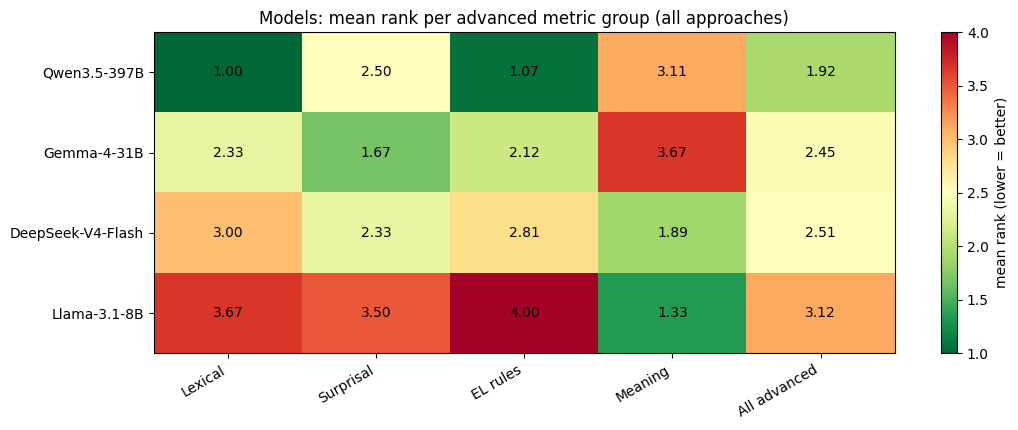

In [17]:
def plot_rank_heatmap(rank_table, title, file_name):
    fig, ax = plt.subplots(figsize=(1.6 * rank_table.shape[1] + 3, 0.6 * rank_table.shape[0] + 2))
    im = ax.imshow(rank_table.values, cmap="RdYlGn_r", aspect="auto")
    ax.set_xticks(range(rank_table.shape[1]))
    ax.set_xticklabels(rank_table.columns, rotation=30, ha="right")
    ax.set_yticks(range(rank_table.shape[0]))
    ax.set_yticklabels(rank_table.index)
    for i in range(rank_table.shape[0]):
        for j in range(rank_table.shape[1]):
            ax.text(j, i, f"{rank_table.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
    plt.colorbar(im, ax=ax, label="mean rank (lower = better)")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, file_name), dpi=150)
    plt.show()


plot_rank_heatmap(model_rank, "Models: mean rank per advanced metric group (all approaches)", "Advanced_LLM_Comparison_Rank.png")

# 9. Experiment 3 – Which approach is best?

Same test as notebook 4: Friedman over the 3 approaches, then pairwise paired tests (Shapiro–Wilk → paired t-test or Wilcoxon) with Bonferroni correction.
Done per model (n = 10) and for all models pooled (n = 40).

In [18]:
def paired_test(a, b):
    diff = a - b
    if np.allclose(diff, 0):
        return 1.0
    if stats.shapiro(diff).pvalue > 0.05:
        return stats.ttest_rel(a, b).pvalue
    return stats.wilcoxon(a, b).pvalue


def compare_approaches(df):
    rows = []
    for metric in ADV_METRICS:
        tmp = pd.DataFrame({a: df[f"{metric}_{a}"].astype(float).values for a in APPROACHES}).dropna()
        n, k = tmp.shape
        stat, p = friedmanchisquare(*[tmp[a] for a in APPROACHES])
        W = stat / (n * (k - 1)) if not np.isnan(stat) else np.nan
        means = tmp.mean()
        best = means.idxmax() if metric in HIGHER_BETTER else means.idxmin()

        beats = []
        if p < 0.05:
            pairs = list(combinations(APPROACHES, 2))
            adj = multipletests([paired_test(tmp[a], tmp[b]) for a, b in pairs], method="bonferroni")[1]
            for (a, b), pa in zip(pairs, adj):
                if pa < 0.05 and best in (a, b):
                    other = b if best == a else a
                    if is_better(metric, means[best], means[other]):
                        beats.append(other)

        row = {"Metric": metric, "n": n, "Friedman_p": round(p, 5), "Kendalls_W": round(W, 3)}
        row.update({f"{a}_mean": round(means[a], 3) for a in APPROACHES})
        row.update({"Winner": best, "Significant": bool(beats), "Winner_better_than": ", ".join(beats) or "–"})
        rows.append(row)
    return pd.DataFrame(rows)


approach_results = {}
for name, df in adv.items():
    approach_results[name] = compare_approaches(df)
pooled = pd.concat(adv.values(), ignore_index=True)
approach_results["All models"] = compare_approaches(pooled)
approach_results["All without Llama"] = compare_approaches(
    pd.concat([df for n, df in adv.items() if n != "Llama-3.1-8B"], ignore_index=True))

for key, res in approach_results.items():
    print(f"\n======================= {key} =======================")
    print(res.to_string(index=False))
    res.to_csv(os.path.join(RESULTS_DIR, f"Advanced_Approach_Comparison_{key.replace(' ', '_')}.csv"), index=False)


======================= DeepSeek-V4-Flash =======================
       Metric  n  Friedman_p  Kendalls_W  Approach_1_mean  Approach_2_mean  Approach_3_mean     Winner  Significant     Winner_better_than
        MATTR 10     0.49659       0.070            0.792            0.782            0.795 Approach_2        False                      –
         MTLD 10     0.14957       0.190           78.505           71.210           79.698 Approach_2        False                      –
         Zipf 10     0.49659       0.070            5.611            5.596            5.543 Approach_1        False                      –
    RareWords 10     0.61436       0.049            4.994            4.804            5.894 Approach_2        False                      –
    Surprisal 10     0.12246       0.210            5.709            5.338            5.679 Approach_2        False                      –
 Surprisal_SD 10     0.33202       0.110            4.683            4.262            4.877 Approac

=========== Wins per approach ===========
                             DeepSeek-V4-Flash  Gemma-4-31B  Llama-3.1-8B  Qwen3.5-397B  All models  All without Llama
Wins             Approach_1                  5            8            12             9          12                  7
                 Approach_2                 10            4             0             2           0                  6
                 Approach_3                  1            4             4             5           4                  3
Significant wins Approach_1                  2            0            12             0           7                  0
                 Approach_2                  2            0             0             0           0                  0
                 Approach_3                  0            0             3             0           1                  0



=========== Mean rank per metric group (1 = best of 3, averaged over the 4 models) ===========
            Lexical  Surprisal  EL rules  Meaning  All advanced
Approach_1     1.31       2.12      1.61     2.25          1.82
Approach_2     2.09       1.62      2.16     2.25          2.03
Approach_3     2.59       2.25      2.23     1.50          2.14


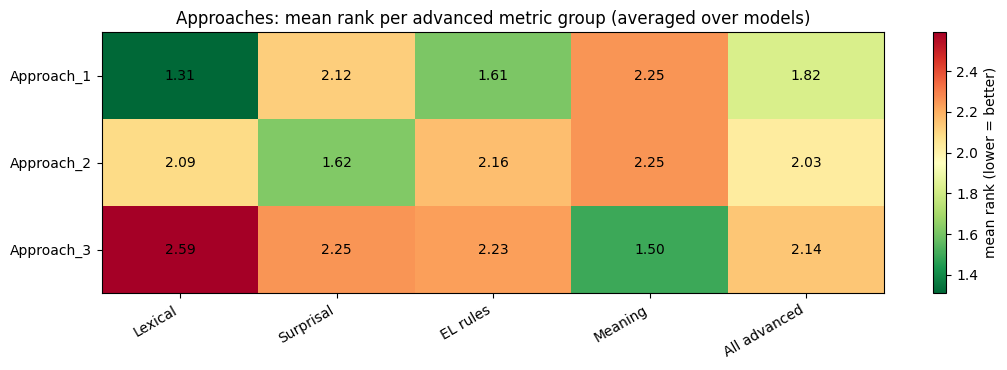

In [19]:
print("=========== Wins per approach ===========")
approach_wins = pd.concat({key: wins_table({key: res}, APPROACHES)[("Wins", key)] for key, res in approach_results.items()}, axis=1)
approach_sig = pd.concat({key: wins_table({key: res}, APPROACHES)[("Significant wins", key)] for key, res in approach_results.items()}, axis=1)
approach_wins.columns = list(approach_results)
approach_sig.columns = list(approach_results)
print(pd.concat({"Wins": approach_wins, "Significant wins": approach_sig}))

approach_rank = group_rank_table({k: v for k, v in approach_results.items() if k in MODELS}, APPROACHES)
print("\n=========== Mean rank per metric group (1 = best of 3, averaged over the 4 models) ===========")
print(approach_rank)
approach_rank.to_csv(os.path.join(RESULTS_DIR, "Advanced_Approach_Comparison_Mean_Rank.csv"))
plot_rank_heatmap(approach_rank, "Approaches: mean rank per advanced metric group (averaged over models)", "Advanced_Approach_Comparison_Rank.png")

# 10. Overall ranking of model + approach combinations

All 12 combinations are ranked per metric (1 = best). We average these ranks per metric group and over all advanced metrics.
The ranking with the **10 paper metrics** (notebook 4) is added for comparison.

In [20]:
combo_means = pd.DataFrame({
    f"{name} | {a}": {m: df[f"{m}_{a}"].mean() for m in ADV_METRICS} for name, df in adv.items() for a in APPROACHES
}).T
combo_ranks = pd.DataFrame({m: combo_means[m].rank(ascending=m not in HIGHER_BETTER) for m in ADV_METRICS})

ranking = pd.DataFrame({group: combo_ranks[metrics].mean(axis=1) for group, metrics in GROUPS.items()})
ranking["All advanced"] = combo_ranks.mean(axis=1)

basic_file = os.path.join(RESULTS_DIR, "Overall_Ranking_Model_Approach.csv")
if os.path.exists(basic_file):
    ranking["Paper metrics (nb 4)"] = pd.read_csv(basic_file, index_col=0)["Mean_rank"]

ranking = ranking.round(2).sort_values("All advanced")
ranking.to_csv(os.path.join(RESULTS_DIR, "Advanced_Overall_Ranking.csv"))
ranking

,Lexical,Surprisal,EL rules,Meaning,All advanced,Paper metrics (nb 4)
Qwen3.5-397B | Approach_3,2.00,4.0,2.57,7.67,3.56,3.6
Qwen3.5-397B | Approach_1,1.00,8.5,1.71,9.33,3.81,2.1
Qwen3.5-397B | Approach_2,3.25,7.0,2.71,7.67,4.31,3.5
Gemma-4-31B | Approach_1,5.50,4.0,4.29,10.00,5.62,4.1
DeepSeek-V4-Flash | Approach_2,7.00,1.5,6.57,6.67,6.06,6.4
Gemma-4-31B | Approach_2,5.00,3.5,5.86,10.33,6.19,6.6
Gemma-4-31B | Approach_3,8.00,4.5,5.14,9.67,6.62,6.3
DeepSeek-V4-Flash | Approach_1,7.75,8.5,8.29,3.33,7.25,7.1
Llama-3.1-8B | Approach_1,6.00,5.5,9.86,5.67,7.56,8.8
DeepSeek-V4-Flash | Approach_3,9.50,8.0,8.14,4.67,7.81,8.2


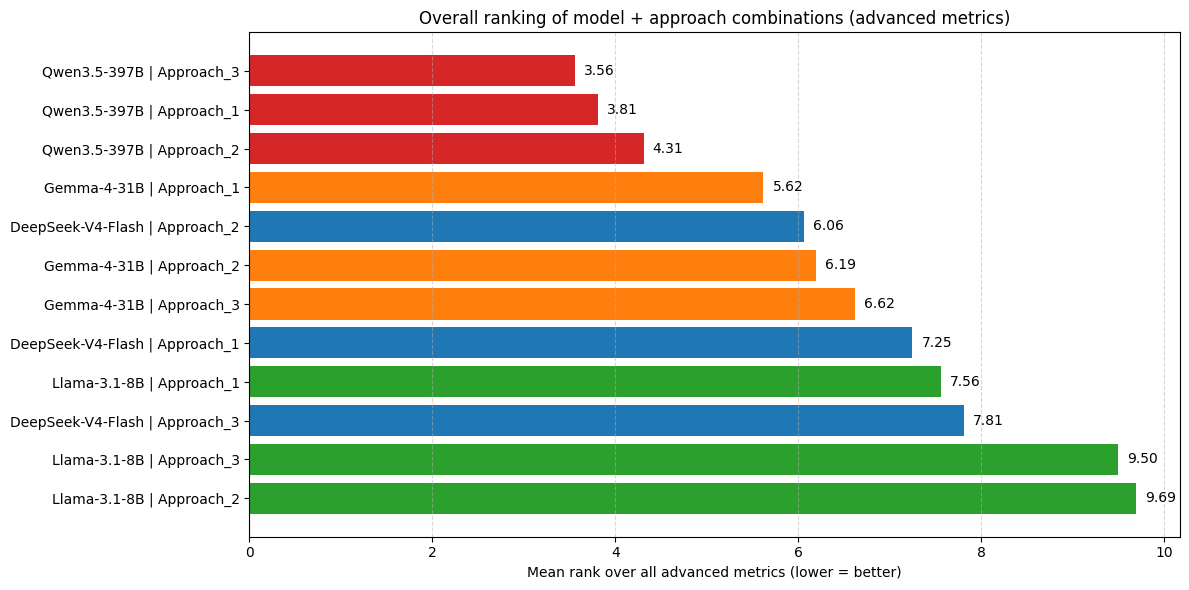

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [MODEL_COLORS[i.split(" | ")[0]] for i in ranking.index]
ax.barh(ranking.index[::-1], ranking["All advanced"][::-1], color=colors[::-1])
for y, v in enumerate(ranking["All advanced"][::-1]):
    ax.text(v + 0.1, y, f"{v:.2f}", va="center")
ax.set_xlabel("Mean rank over all advanced metrics (lower = better)")
ax.set_title("Overall ranking of model + approach combinations (advanced metrics)")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "Advanced_Overall_Ranking.png"), dpi=150)
plt.show()

# 11. Simplicity vs. meaning preservation

A good Easy Language translation must be **simple and keep the content**. The scatter plot shows each of the 12 combinations
by readability (LIX, from notebook 1; lower = simpler) and content Coverage. The best combinations are at the **top left**.

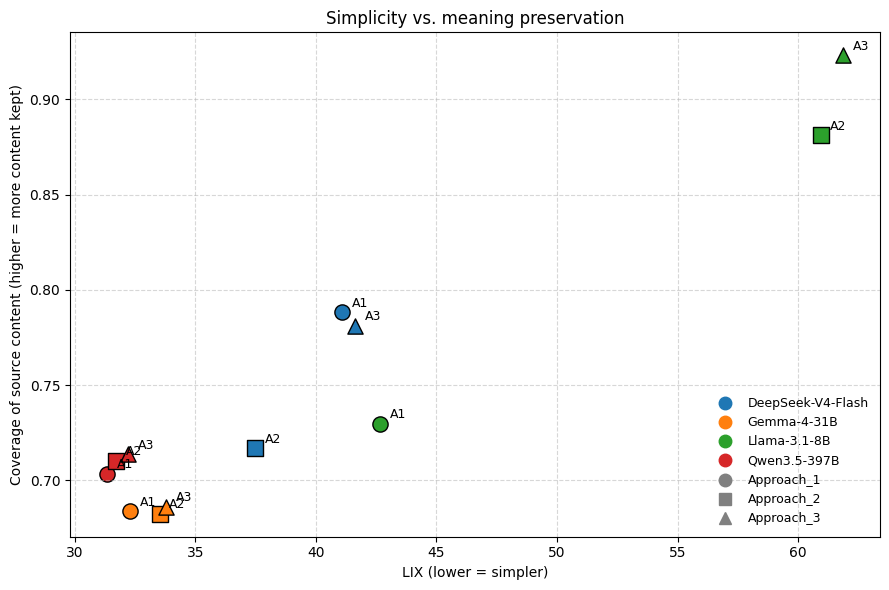

In [22]:
basic = {name: pd.read_csv(os.path.join(DATA_DIR, folder, f"Matrix_Scores_{folder}.csv")).sort_values("ID").reset_index(drop=True)
         for name, folder in MODELS.items()}
markers = {"Approach_1": "o", "Approach_2": "s", "Approach_3": "^"}

fig, ax = plt.subplots(figsize=(9, 6))
for name in MODELS:
    for a in APPROACHES:
        x, y = basic[name][f"LIX_{a}"].mean(), adv[name][f"Coverage_{a}"].mean()
        ax.scatter(x, y, s=120, color=MODEL_COLORS[name], marker=markers[a], edgecolor="black")
        ax.annotate(a.replace("Approach_", "A"), (x, y), textcoords="offset points", xytext=(7, 4), fontsize=9)
handles = [plt.Line2D([], [], color=MODEL_COLORS[n], marker="o", linestyle="", markersize=9) for n in MODELS]
handles += [plt.Line2D([], [], color="grey", marker=markers[a], linestyle="", markersize=9) for a in APPROACHES]
ax.legend(handles, list(MODELS) + APPROACHES, frameon=False, fontsize=9, loc="lower right")
ax.set_xlabel("LIX (lower = simpler)")
ax.set_ylabel("Coverage of source content (higher = more content kept)")
ax.set_title("Simplicity vs. meaning preservation")
ax.grid(linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "Advanced_Simplicity_vs_Meaning.png"), dpi=150)
plt.show()

## Do the automatic metrics agree with the LLM judge?

Spearman correlations over the 120 outputs between the judge ratings and the automatic metrics (the paper metrics plus the advanced ones).
This shows which automatic metrics capture what the judge rates as good Easy Language.

In [23]:
if HAS_JUDGE:
    PAPER_METRICS = ["TTR", "LD", "WR", "MDD", "SI", "Cross", "WSF", "LIX", "FRE", "Fog"]
    long_rows = []
    for name in MODELS:
        for a in APPROACHES:
            for i in range(len(adv[name])):
                row = {m: basic[name].loc[i, f"{m}_{a}"] for m in PAPER_METRICS}
                row.update({m: adv[name].loc[i, f"{m}_{a}"] for m in LEXICAL + SURPRISAL + EL_RULES + MEANING + JUDGE})
                long_rows.append(row)
    long_df = pd.DataFrame(long_rows)

    auto_metrics = PAPER_METRICS + LEXICAL + SURPRISAL + EL_RULES + MEANING
    corr = pd.DataFrame({j: [spearmanr(long_df[m], long_df[j], nan_policy="omit")[0] for m in auto_metrics] for j in JUDGE},
                        index=auto_metrics).round(2)
    corr.to_csv(os.path.join(RESULTS_DIR, "Advanced_Judge_Correlations.csv"))

    fig, ax = plt.subplots(figsize=(9, 10))
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(JUDGE)))
    ax.set_xticklabels([j.replace("Judge_", "") for j in JUDGE], rotation=30, ha="right")
    ax.set_yticks(range(len(auto_metrics)))
    ax.set_yticklabels(auto_metrics)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title("Automatic metrics vs. LLM judge (n = 120)")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "Advanced_Judge_Correlations.png"), dpi=150)
    plt.show()
else:
    print("No judge ratings yet - set GWDG_API_KEY and run the notebook again.")

No judge ratings yet - set GWDG_API_KEY and run the notebook again.


In [24]:
# Judge: typical problems per model (short comments from the judge)
if HAS_JUDGE:
    for name in MODELS:
        sub = jd[jd["Model"] == name].sort_values("Overall")
        print(f"\n----- {name} (lowest-rated outputs) -----")
        for _, r in sub.head(4).iterrows():
            print(f"  {r['Approach']} {r['ID']:10s} Overall={r['Overall']}: {r['Main_problem']}")

# Findings (automatic advanced metrics)

*The LLM-judge ratings are not included yet: no `GWDG_API_KEY` was set when this notebook was run. Set the key and run the notebook again; the judge results will then be added to every experiment and to the correlation analysis.*

### Legal vs. Medical
* After Holm correction, only **one** difference is significant: Llama-3.1-8B, Approach_1 has higher `EL_Compliance` for legal texts (52 % vs. 28 % of sentences).
* Across models, the trends point the same way (mean d):
  * medical outputs contain **more rare words** (d ≈ −0.9)
  * medical outputs contain **more passive sentences** (d ≈ −0.9)
* This is plausible: medical texts contain drug names and many *wird angewendet* constructions.
* As in notebook 2, the text type has only a small effect on the outputs.

### Which model is best?
* **Qwen3.5-397B is best for simplification.** It wins 32 of 48 metric × approach comparisons (28 of them significant).
  * It has rank 1.0 on lexical metrics and 1.07 on the Easy Language rules.
  * 86–92 % of its sentences follow all six rules.
  * It has the lowest MTLD, the most frequent words and almost no passive, genitive or long compounds.
* **However, Qwen is only 3rd of 4 in meaning preservation.**
  * Coverage ≈ 0.70–0.71 and Precision ≈ 0.58–0.59. The low Precision means it adds many explanations that are not in the source.
  * It keeps about 60 % of the numbers.
* **DeepSeek-V4-Flash keeps the most content among the models that really simplify.**
  * It has the highest Coverage (0.79) and NumberRecall (77 %) in Approach_1.
  * But its outputs are less simple: EL_Compliance is 51–69 %.
* **Gemma-4-31B** is simple, but it **deletes the most content**.
  * Its outputs have only about 44 % of the source length.
  * It keeps only 30–43 % of the numbers and has the lowest Coverage.
* **Llama-3.1-8B** "wins" Coverage, Precision and NumberRecall in Approach_2 and Approach_3, but only because it barely changed the text (LengthRatio 0.79–0.95, EL_Compliance ≈ 11 %).
* **Surprisal:** all simplifying models lower it from 6.9 bits per word (Original) to about 5.3–5.7 bits. The differences between DeepSeek, Gemma and Qwen are small and mostly not significant.

### Which approach is best?
* **All models pooled:** Approach_1 (via English Easy Language) wins 12 of 16 metrics (7 significant). It has the lowest MATTR/MTLD, the most frequent words, the fewest passives, genitives and long words, and the highest EL_Compliance.
  * Approach_3 (direct) preserves the most content (Coverage 0.78, significant).
* **Without Llama**, no difference between the approaches is significant.
  * Approach_1 and Approach_2 win about equally often (7 vs. 6 metrics).
  * Approach_1 keeps slightly more numbers (59 % vs. 48–50 %).
* **Per model:**
  * **DeepSeek:** Approach_2 gives the simplest text (significant on ASL and EL_Compliance), but Approach_1 keeps significantly more content than Approach_2.
  * **Gemma and Qwen:** the approach makes no significant difference.

### Overall
* **Model + approach ranking (advanced metrics):**
  * Top 3: Qwen + Approach_3, Qwen + Approach_1, Qwen + Approach_2. All three Qwen combinations are on top, and they are very close.
  * Next: Gemma + Approach_1 and DeepSeek + Approach_2.
* **Simplicity vs. meaning** (scatter plot):
  * Qwen is simpler **and** keeps more content than Gemma.
  * DeepSeek keeps more content but is less simple.
  * There is no combination that is both very simple and very complete.
* **Conclusion:**
  * Notebooks 1–4 found Qwen to be the best model for simplification. These metrics confirm that.
  * They also show the cost: every model that simplifies strongly loses roughly 30 % of the source content (Coverage ≈ 0.7). Gemma loses the most information.
  * So a meaning/content check (LLM judge or human error analysis) is necessary before choosing a model.
